# Classificação de Frutas — Forma (Fourier) + Textura (GLCM + LBP)

**Visão Computacional — atividade avaliativa**

Este notebook é a **vitrine de apresentação** do projeto. Ele *importa* os módulos de `src/`
(sem reimplementar nada) e percorre o pipeline completo usando o **dataset real** (Fruits 360,
subconjunto curado em `dataset/frutas`), mostrando código, imagens e gráficos lado a lado.

## Roteiro
1. As classes de frutas usadas
2. Pré-processamento passo a passo (resize → cinza → Gauss → Otsu → morfologia)
3. Descritor de **forma**: contorno → FFT (Fourier)
4. Descritores de **textura**: GLCM + LBP
5. Vetor de características final
6. Classificação (StandardScaler + SVM RBF) no dataset real
7. Avaliação: métricas, matriz de confusão, F1 por classe
8. **Exemplos de predições** (galeria Real × Previsto) e os erros do modelo

> **Pré-requisito:** ter rodado `python preparar_dataset.py` (gera `dataset/frutas`).
> Sem dataset, use `python demo.py`, que faz o mesmo pipeline com imagens sintéticas.

## 0. Configuração e imports

Toda a lógica está em `src/` — aqui só orquestramos e visualizamos.

In [2]:
import os, sys, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath('.'))
from src import preprocessamento, extrator_fourier, extrator_textura, classificador, avaliacao

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 4)

# Pasta do dataset curado (gerada por preparar_dataset.py).
PASTA_DATASET = 'dataset/frutas'
assert os.path.isdir(PASTA_DATASET), (
    f"'{PASTA_DATASET}' não encontrado. Rode: python preparar_dataset.py")

CLASSES = sorted(d for d in os.listdir(PASTA_DATASET)
                 if os.path.isdir(os.path.join(PASTA_DATASET, d)))
print('Classes encontradas:', CLASSES)

Classes encontradas: ['Apple', 'Avocado', 'Banana', 'Lemon', 'Orange', 'Pineapple', 'Raspberry', 'Strawberry']


In [3]:
def primeira_imagem(classe):
    """Retorna o caminho da 1ª imagem de uma classe (para os exemplos visuais)."""
    arquivos = sorted(glob.glob(os.path.join(PASTA_DATASET, classe, '*')))
    return arquivos[0]

exemplos = {classe: primeira_imagem(classe) for classe in CLASSES}

## 1. As classes de frutas

Escolhemos 8 frutas com **formas e texturas bem distintas** — isso faz tanto o descritor de
forma (Fourier) quanto os de textura (GLCM/LBP) brilharem: banana alongada, morango cônico com
sementes, abacaxi rugoso, framboesa granulada, etc.

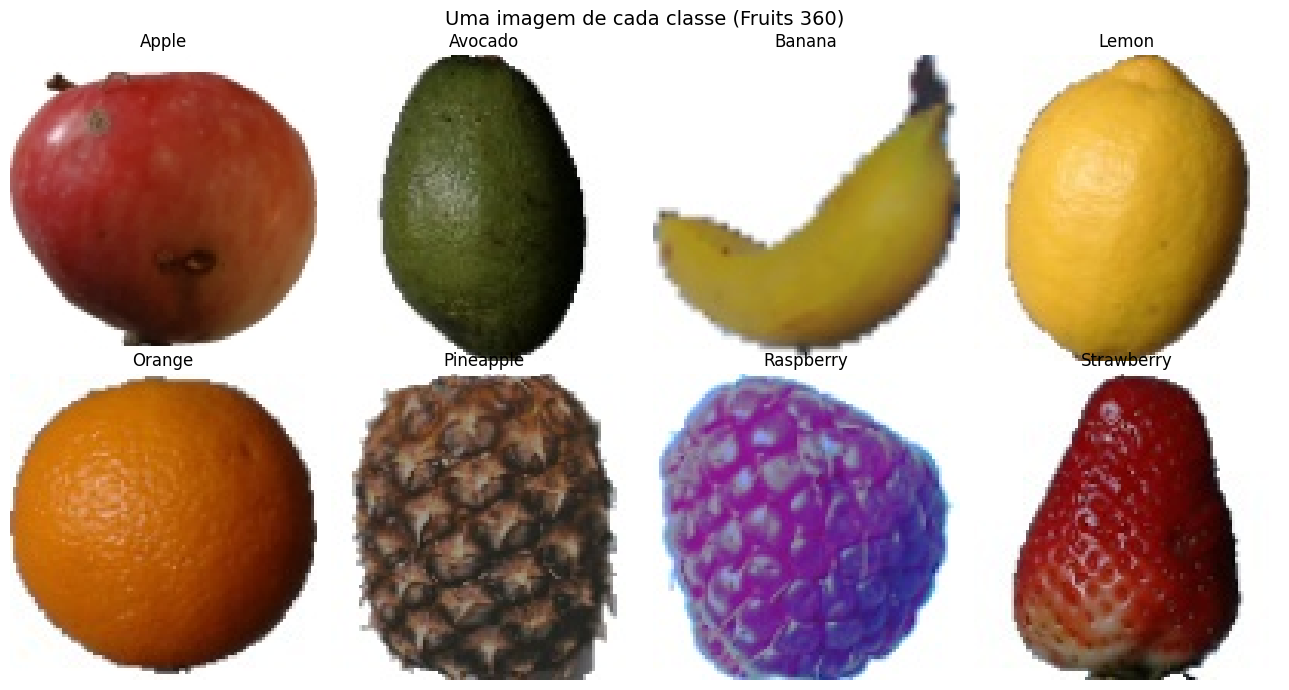

In [4]:
fig, eixos = plt.subplots(2, 4, figsize=(13, 7))
for eixo, classe in zip(eixos.ravel(), CLASSES):
    img = cv2.imread(exemplos[classe])
    eixo.imshow(img[:, :, ::-1])  # BGR -> RGB só para exibir
    eixo.set_title(classe)
    eixo.axis('off')
plt.suptitle('Uma imagem de cada classe (Fruits 360)', fontsize=14)
plt.tight_layout(); plt.show()

## 2. Pré-processamento passo a passo

Usamos o **abacaxi** (textura marcante) para mostrar o efeito de cada etapa. A última imagem
(máscara) é a entrada do descritor de forma e delimita a região usada na textura.

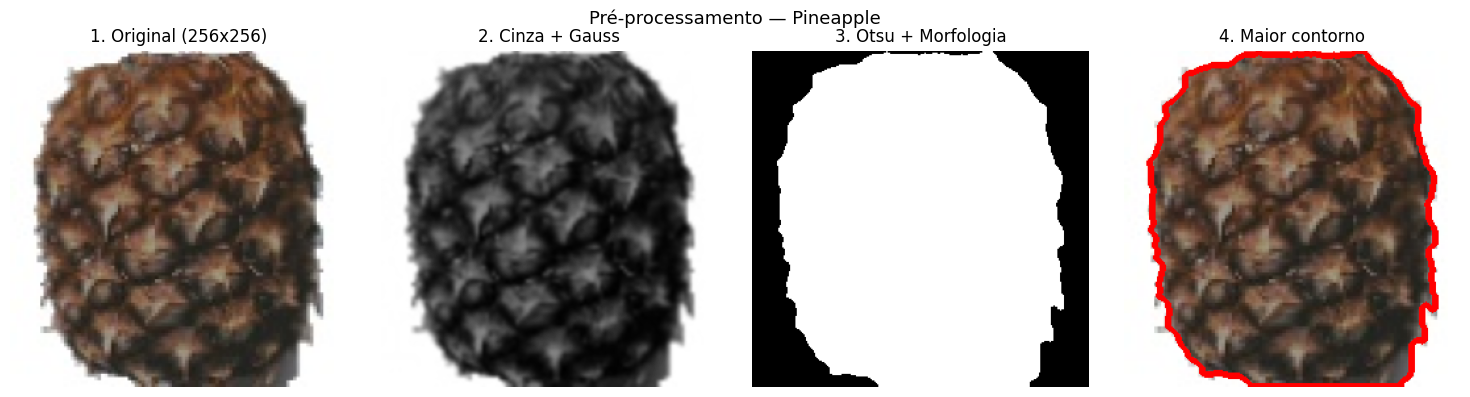

In [5]:
FRUTA_DEMO = 'Pineapple' if 'Pineapple' in CLASSES else CLASSES[0]
dados = preprocessamento.preprocessar(exemplos[FRUTA_DEMO])

fig, eixos = plt.subplots(1, 4, figsize=(15, 4))
eixos[0].imshow(dados['original'][:, :, ::-1]);   eixos[0].set_title('1. Original (256x256)')
eixos[1].imshow(dados['suavizada'], cmap='gray'); eixos[1].set_title('2. Cinza + Gauss')
eixos[2].imshow(dados['mascara'], cmap='gray');   eixos[2].set_title('3. Otsu + Morfologia')

contorno = extrator_fourier.encontrar_maior_contorno(dados['mascara'])
vis = dados['original'].copy()
cv2.drawContours(vis, [contorno], -1, (0, 0, 255), 3)
eixos[3].imshow(vis[:, :, ::-1]);                 eixos[3].set_title('4. Maior contorno')
for e in eixos: e.axis('off')
plt.suptitle(f'Pré-processamento — {FRUTA_DEMO}', fontsize=13)
plt.tight_layout(); plt.show()

## 3. Descritor de forma — Fourier

**Ideia:** percorremos o contorno e tratamos cada ponto `(x, y)` como um número complexo `z = x + i·y`.
A FFT desse sinal gera os *descritores de Fourier*. Com poucas normalizações eles ficam invariantes a
**translação** (remove DC), **rotação/ponto inicial** (usa o módulo) e **escala** (divide pelo 1º coeficiente).

À esquerda, a **assinatura de forma** (distância ao centroide — intuição visual); à direita, os
**coeficientes de Fourier** que entram no vetor de características.

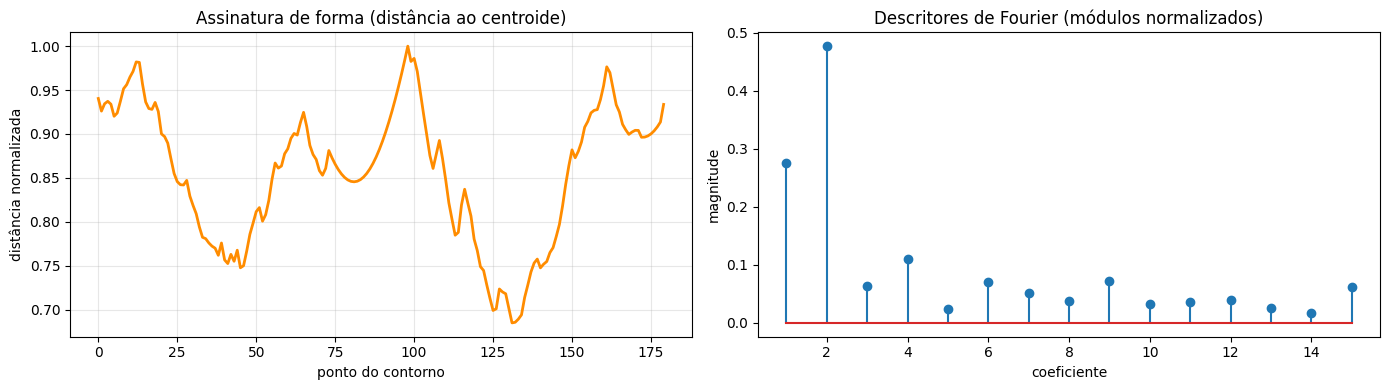

Vetor de Fourier (15 coef): [0.275 0.477 0.063 0.11  0.024 0.07  0.052 0.037 0.072 0.032 0.036 0.04
 0.026 0.016 0.062]


In [6]:
assinatura = extrator_fourier.assinatura_distancia_centroide(dados['mascara'])
coef = extrator_fourier.descritor_fourier(dados['mascara'], n_coeficientes=15)

fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
eixos[0].plot(assinatura, color='darkorange', lw=2)
eixos[0].set_title('Assinatura de forma (distância ao centroide)')
eixos[0].set_xlabel('ponto do contorno'); eixos[0].set_ylabel('distância normalizada'); eixos[0].grid(alpha=0.3)

eixos[1].stem(range(1, len(coef)+1), coef)
eixos[1].set_title('Descritores de Fourier (módulos normalizados)')
eixos[1].set_xlabel('coeficiente'); eixos[1].set_ylabel('magnitude')
plt.tight_layout(); plt.show()
print('Vetor de Fourier (15 coef):', np.round(coef, 3))

### Comparando a assinatura entre formas distintas
Banana (alongada), Apple (redonda) e Strawberry (cônica) têm assinaturas bem diferentes — é isso
que o classificador aprende a separar.

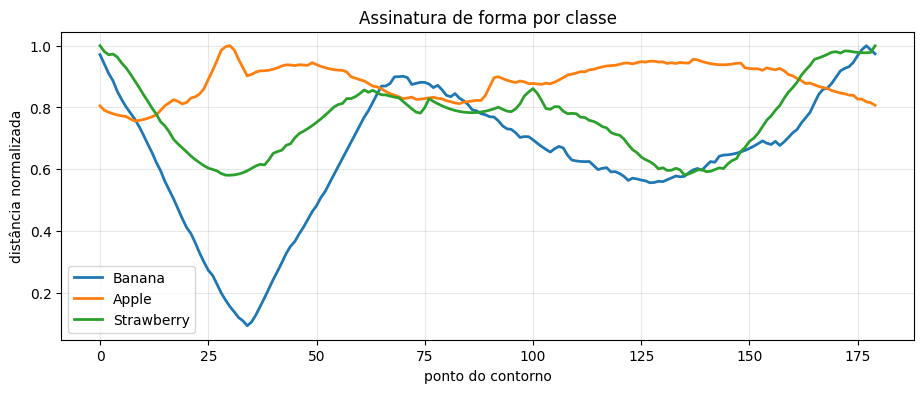

In [7]:
comparar = [c for c in ['Banana', 'Apple', 'Strawberry'] if c in CLASSES] or CLASSES[:3]
plt.figure(figsize=(11, 4))
for classe in comparar:
    d = preprocessamento.preprocessar(exemplos[classe])
    plt.plot(extrator_fourier.assinatura_distancia_centroide(d['mascara']), lw=2, label=classe)
plt.title('Assinatura de forma por classe'); plt.xlabel('ponto do contorno')
plt.ylabel('distância normalizada'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 4. Descritores de textura — GLCM + LBP

- **GLCM**: estatísticas de segunda ordem (`contrast`, `dissimilarity`, `homogeneity`, `energy`, `correlation`).
- **LBP**: histograma de padrões binários locais (robusto à iluminação).

O abacaxi tem textura rica — ótimo para enxergar o que esses descritores capturam.

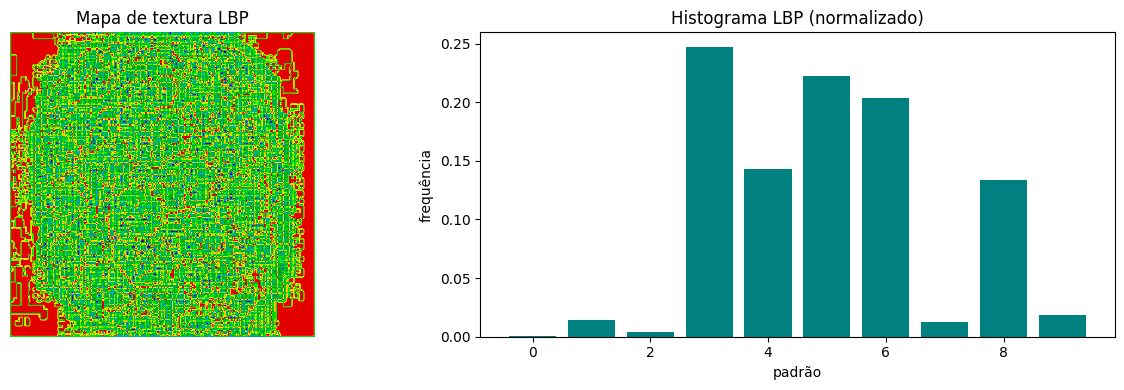

GLCM:
  contrast      : 3.9723
  dissimilarity : 0.7033
  homogeneity   : 0.7785
  energy        : 0.2913
  correlation   : 0.9166


In [8]:
glcm = extrator_textura.extrair_glcm(dados['cinza'], dados['mascara'])
lbp_hist = extrator_textura.extrair_lbp(dados['cinza'], dados['mascara'])
lbp_map = extrator_textura.mapa_lbp(dados['cinza'])

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
eixos[0].imshow(lbp_map, cmap='nipy_spectral'); eixos[0].set_title('Mapa de textura LBP'); eixos[0].axis('off')
eixos[1].bar(range(len(lbp_hist)), lbp_hist, color='teal')
eixos[1].set_title('Histograma LBP (normalizado)'); eixos[1].set_xlabel('padrão'); eixos[1].set_ylabel('frequência')
plt.tight_layout(); plt.show()

print('GLCM:')
for nome, valor in zip(extrator_textura.PROPRIEDADES_GLCM, glcm):
    print(f'  {nome:<14}: {valor:.4f}')

## 5. Vetor de características final

Concatenação: **[ Fourier (forma) | GLCM (textura) | LBP (textura) ]**.

In [9]:
vetor = classificador.montar_vetor_caracteristicas(dados)
print('Tamanho do vetor:', vetor.shape[0])
print('  - Fourier : 15')
print('  - GLCM    :', len(extrator_textura.PROPRIEDADES_GLCM))
print('  - LBP     :', len(lbp_hist))
print('\nPrimeiros valores:', np.round(vetor[:10], 3))

Tamanho do vetor: 30
  - Fourier : 15
  - GLCM    : 5
  - LBP     : 10

Primeiros valores: [0.275 0.477 0.063 0.11  0.024 0.07  0.052 0.037 0.072 0.032]


## 6. Treinando e avaliando no dataset real

Carregamos **todas as imagens** de `dataset/frutas`, extraímos os vetores e treinamos o
**SVM (RBF)** dentro de um `Pipeline` com `StandardScaler`. Pedimos também os **caminhos** das
imagens (`retornar_caminhos=True`) para conseguir mostrar exemplos das predições mais adiante.

A divisão é **70% treino / 30% teste** — o modelo é avaliado em imagens que nunca viu.

In [10]:
import logging; logging.disable(logging.INFO)  # silencia os logs do main no notebook
import main
from sklearn.model_selection import train_test_split

X, y, classes, caminhos = main.carregar_dataset(PASTA_DATASET, retornar_caminhos=True)
print(f'{X.shape[0]} amostras | {X.shape[1]} características | {len(classes)} classes')

# train_test_split divide X, y E os caminhos de forma alinhada.
X_tr, X_te, y_tr, y_te, p_tr, p_te = train_test_split(
    X, y, caminhos, test_size=0.3, random_state=42, stratify=y)

modelo = classificador.criar_classificador()
classificador.treinar(modelo, X_tr, y_tr)   # .fit() -> APRENDE com os 70%
y_pred = classificador.prever(modelo, X_te) # .predict() -> TESTA nos 30%

metricas = avaliacao.calcular_metricas(y_te, y_pred)
print()
for k, v in metricas.items():
    print(f'{k:>9}: {v:.3f}')

2000 amostras | 30 características | 8 classes

 acuracia: 0.970
 precisao: 0.972
   recall: 0.970
       f1: 0.970


## 7. Matriz de confusão, F1 por classe e relatório

Reaproveitamos as funções de `avaliacao.py` (que salvam PNG em `resultados/`) e exibimos inline.

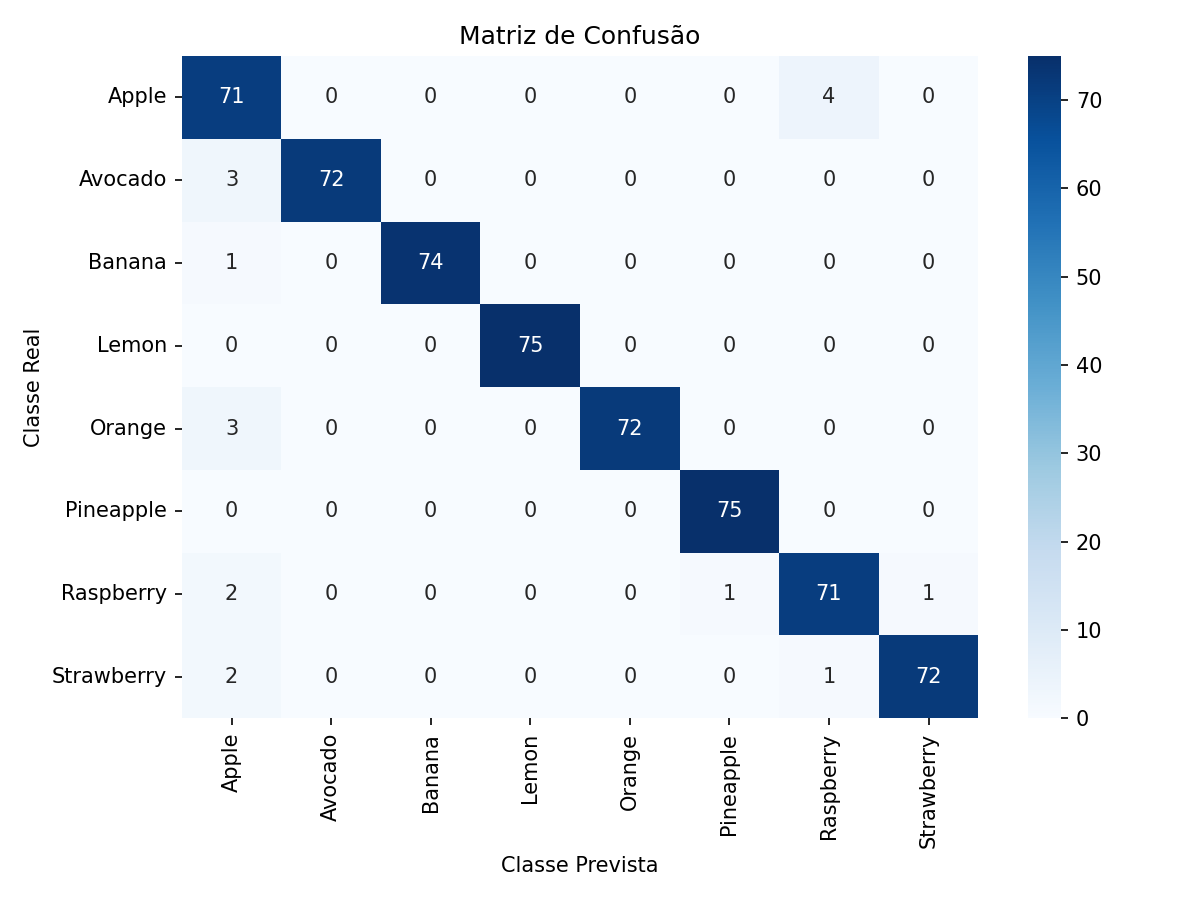

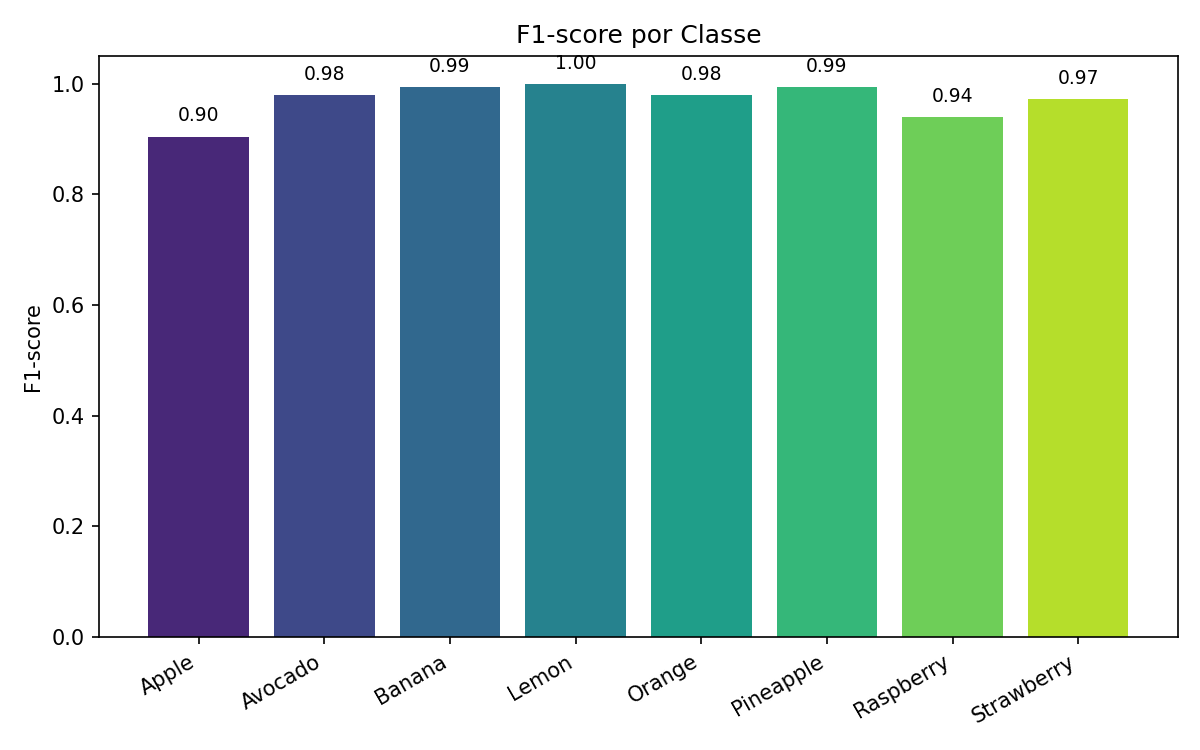

,precision,recall,f1-score,support
Apple,0.866,0.947,0.904,75.00
Avocado,1.000,0.960,0.980,75.00
Banana,1.000,0.987,0.993,75.00
Lemon,1.000,1.000,1.000,75.00
Orange,1.000,0.960,0.980,75.00
Pineapple,0.987,1.000,0.993,75.00
Raspberry,0.934,0.947,0.940,75.00
Strawberry,0.986,0.960,0.973,75.00
accuracy,0.970,0.970,0.970,0.97
macro avg,0.972,0.970,0.970,600.00


In [11]:
from IPython.display import Image, display

avaliacao.garantir_pasta('resultados')
avaliacao.plotar_matriz_confusao(y_te, y_pred, classes, 'resultados/matriz_confusao.png')
avaliacao.plotar_f1_por_classe(y_te, y_pred, classes, 'resultados/f1_por_classe.png')
df = avaliacao.salvar_relatorio_csv(y_te, y_pred, classes, 'resultados/relatorio_metricas.csv')

display(Image('resultados/matriz_confusao.png'))
display(Image('resultados/f1_por_classe.png'))
df.round(3)

## 8. Exemplos de predições (Real × Previsto)

A matriz de confusão mostra os números; aqui mostramos as **imagens de teste de verdade** com o
rótulo real e o que o modelo previu. **Verde = acerto**, **vermelho = erro**.

Lembrando: são imagens do conjunto de teste, que o modelo **não viu** durante o treino.

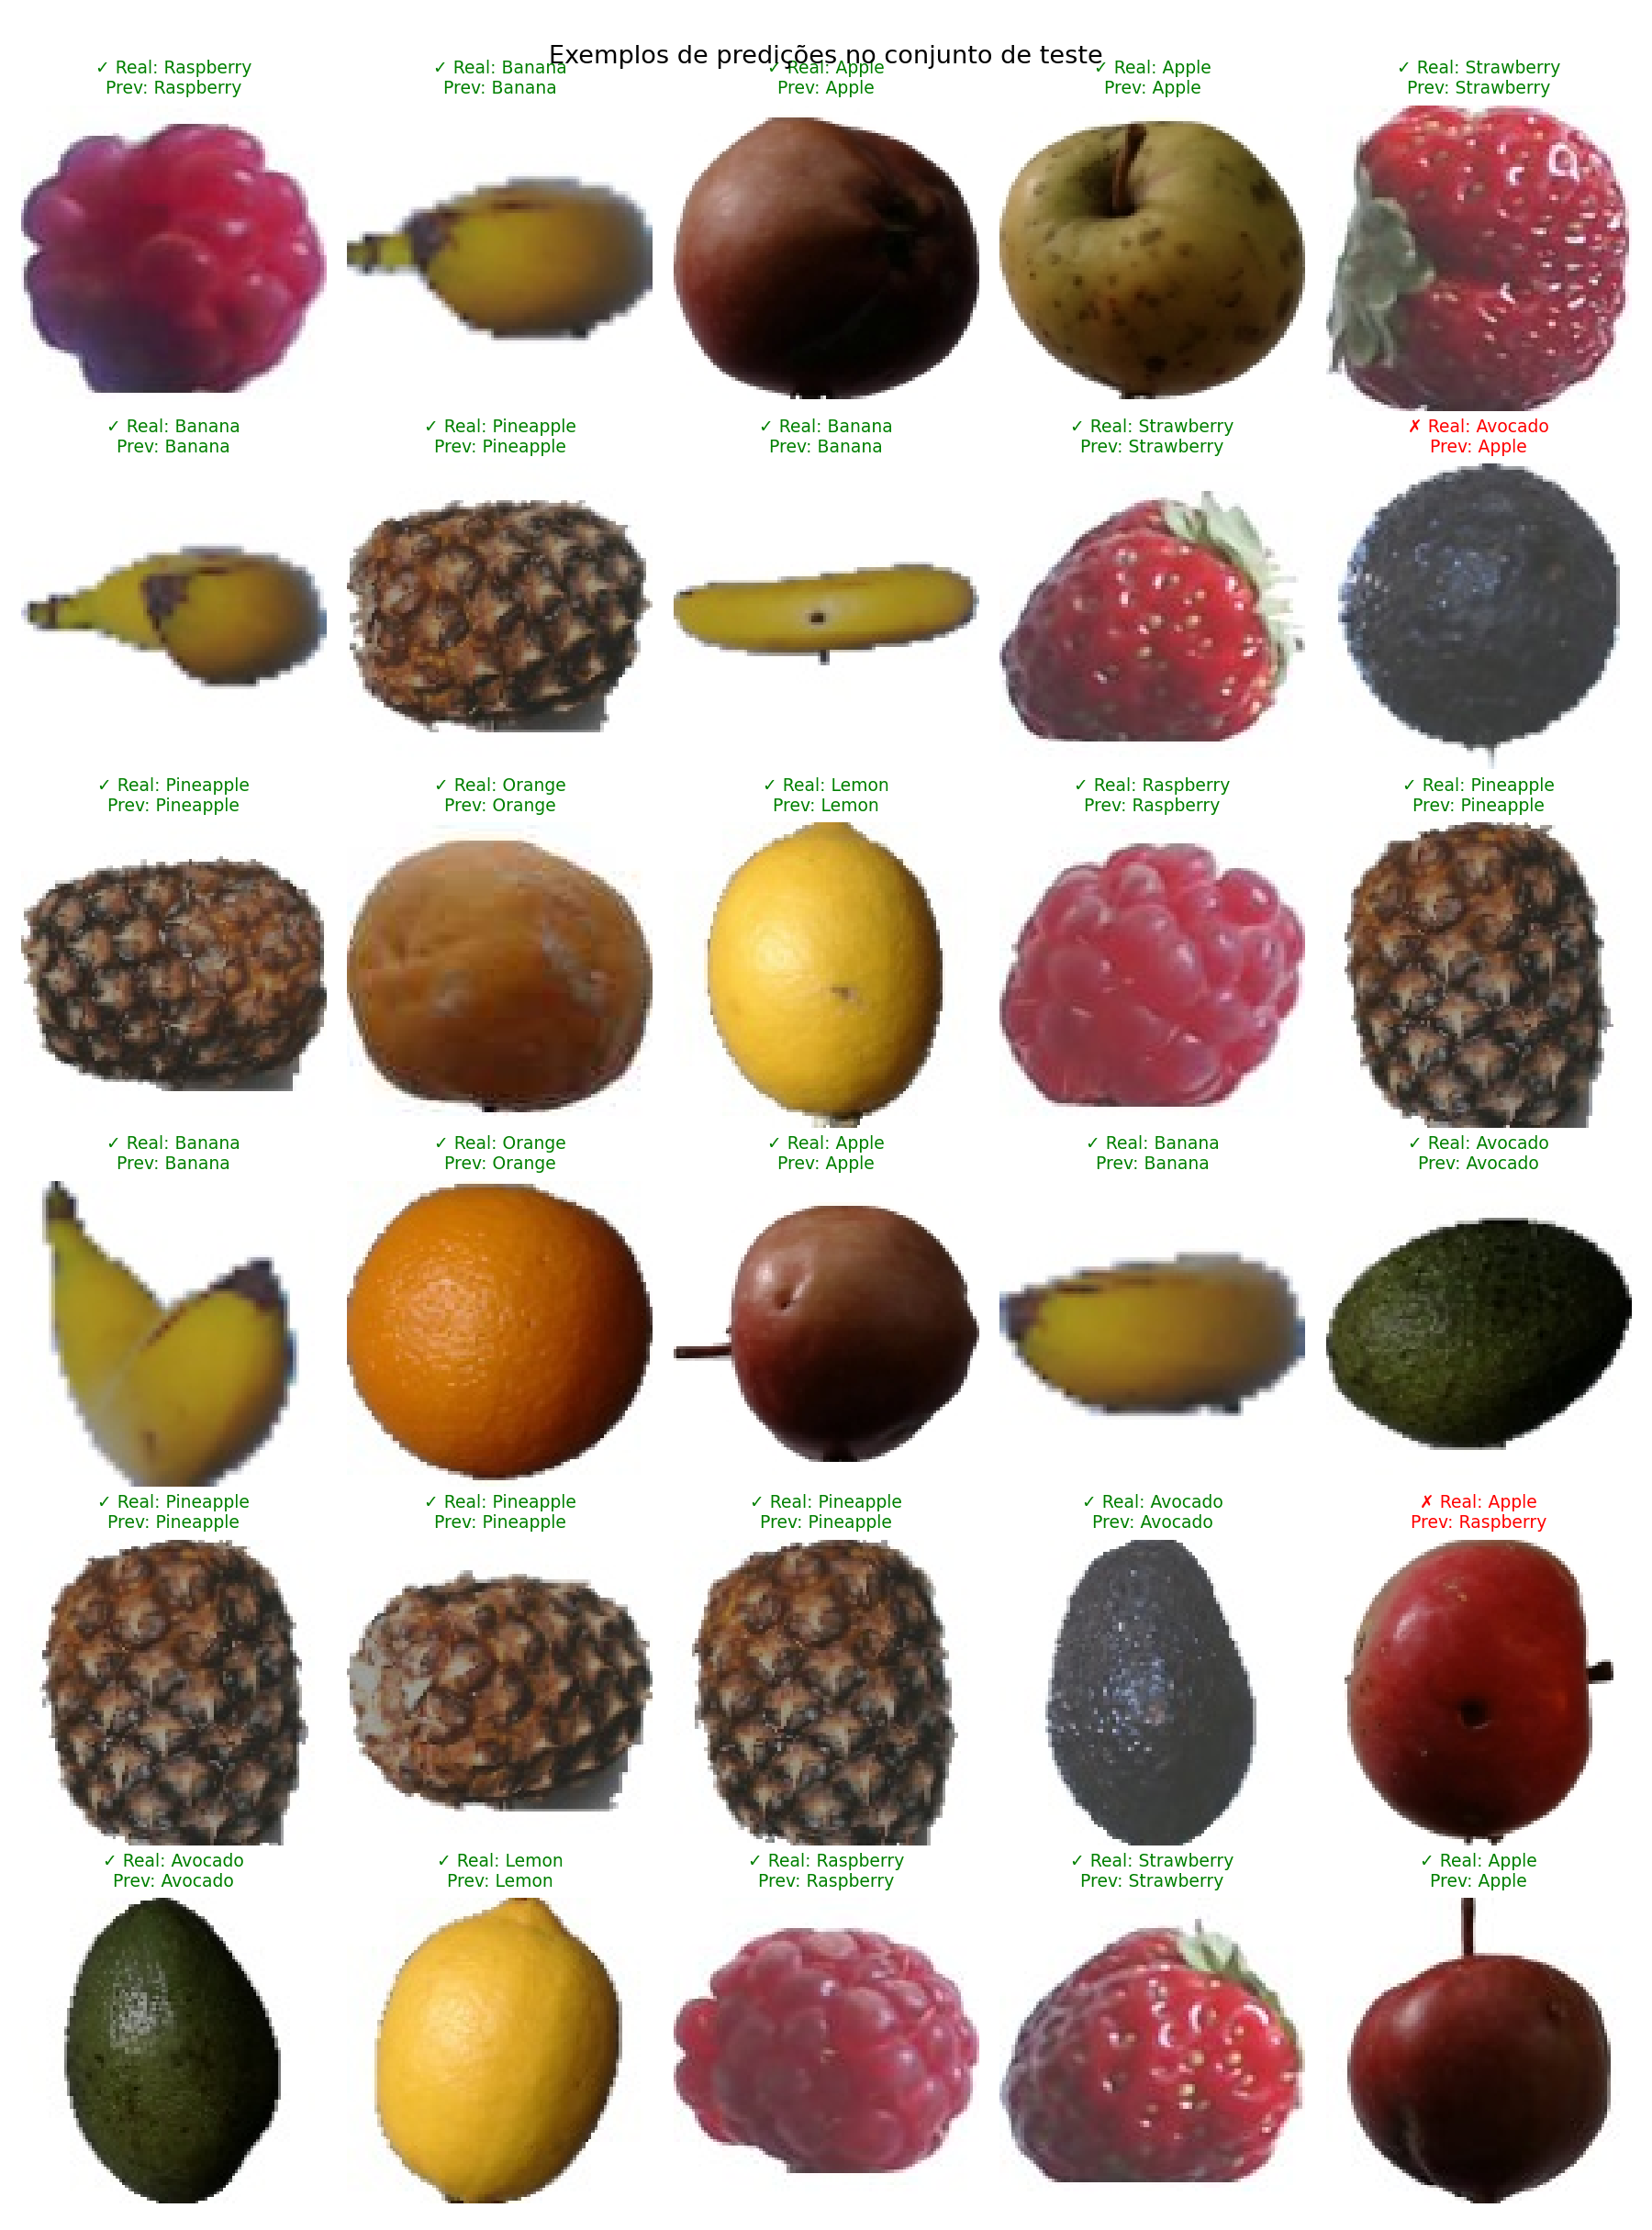

In [12]:
# Amostra geral de predições (a maioria deve estar verde).
avaliacao.plotar_amostras_preditas(
    p_te, y_te, y_pred, classes, 'resultados/exemplos_predicoes.png', n=30)
display(Image('resultados/exemplos_predicoes.png'))

### E onde o modelo erra?
Mostrar os erros é honesto e didático — geralmente são frutas parecidas em cor/forma
(ex.: variedades de maçã, framboesa × morango).

Total de erros no teste: 18 de 600 (3.0%)


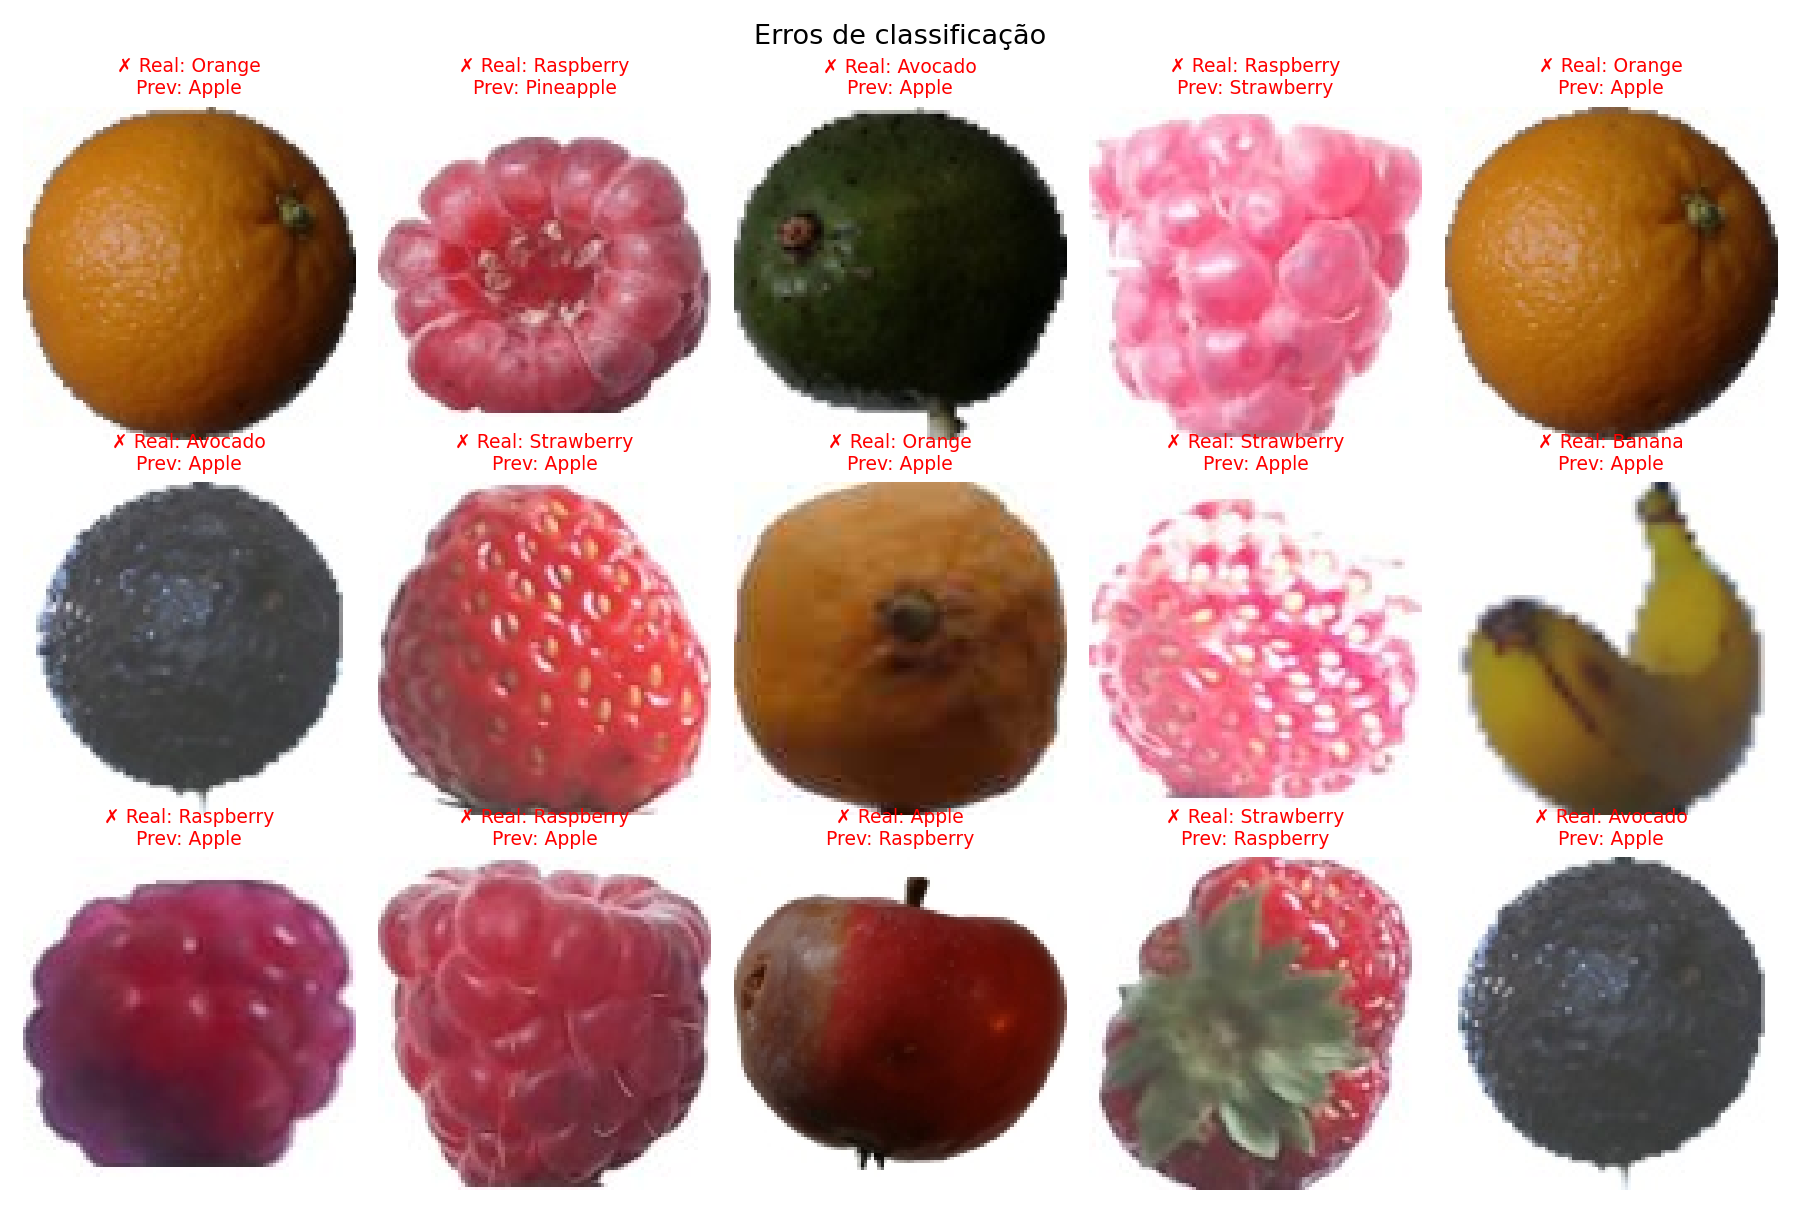

In [13]:
n_erros = int((y_te != y_pred).sum())
print(f'Total de erros no teste: {n_erros} de {len(y_te)} ({n_erros/len(y_te):.1%})')

avaliacao.plotar_amostras_preditas(
    p_te, y_te, y_pred, classes, 'resultados/erros_classificacao.png',
    n=15, apenas_erros=True)
display(Image('resultados/erros_classificacao.png'))

## 9. Conclusões

- O pipeline combina **forma** (descritores de Fourier) e **textura** (GLCM + LBP) em um único
  vetor de 30 características, classificado por **SVM com kernel RBF**.
- No subconjunto curado do Fruits 360 (8 classes, 250 imgs/classe) obtivemos **~97% de acurácia**,
  com **todas as classes em F1 ≥ 0,90**.
- A divisão **70% treino / 30% teste** garante que a avaliação seja feita em imagens novas — os
  poucos erros tendem a ocorrer entre frutas visualmente parecidas.
- Escolher poucas classes **bem distintas** é uma decisão metodológica consciente: como os
  descritores são *handcrafted* (não deep learning), classes quase idênticas do dataset original
  (ex.: `Apple 10` vs `Apple 11`) só introduziriam confusão e piorariam as métricas.
- O pipeline é **escalável**: para rodar em todas as 260 classes, basta
  `python main.py --dataset dataset/archive/fruits-360_100x100/fruits-360/Training`.

**Reprodutibilidade:**
```bash
uv venv .venv --python 3.12
uv pip install --python .venv -r requirements.txt jupyter ipykernel
python preparar_dataset.py          # monta dataset/frutas
jupyter notebook apresentacao.ipynb # este notebook
```